# AE4 — Métricas y visualización del abandono de clientes

**Proyecto integrador · Etapa 3: métricas y visualización de datos**

Este notebook:

1. carga el dataset preparado y las tablas de resultados de la AE3;
2. **verifica** que las tablas coinciden con un nuevo cálculo desde el dataset (mismas cifras que mostrará Streamlit);
3. documenta cada métrica (cálculo y unidad) por pregunta de negocio;
4. genera los gráficos estáticos (`AE4/resultados/graficos/*.png`) que se usan en el documento final.

La aplicación interactiva está en `AE4/app/streamlit_app.py` y usa los mismos datos y textos (`AE4/app/contenido.py`).

## 1. Preparar el entorno

In [1]:
import sys
import warnings
from pathlib import Path

# Buscamos la carpeta raíz del proyecto (la que contiene src/clases_po).
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent
# Agregamos src (clases del proyecto) y AE4/app (textos compartidos con Streamlit).
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "AE4" / "app"))
warnings.filterwarnings("ignore")

import matplotlib
matplotlib.use("Agg")              # genera imágenes sin abrir ventanas
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from clases_po import tabla_abandono
import contenido as C

CARPETA_TABLAS = ROOT / "AE3" / "resultados" / "tablas"
CARPETA_GRAFICOS = ROOT / "AE4" / "resultados" / "graficos"
CARPETA_GRAFICOS.mkdir(parents=True, exist_ok=True)
print("Listo. Gráficos en:", CARPETA_GRAFICOS.relative_to(ROOT).as_posix())

Listo. Gráficos en: AE4/resultados/graficos


## 2. Cargar el dataset preparado y las tablas de la AE3

In [2]:
# Dataset preparado en AE3 (7043 clientes x 28 columnas).
df = pd.read_csv(ROOT / "AE3" / "datos" / "churn_preparado.csv", encoding="utf-8-sig")

# El CSV no guarda el orden de las categorías: lo restablecemos para que los gráficos salgan ordenados.
df["tipo_contrato"] = pd.Categorical(df["tipo_contrato"], ["Mes a mes", "Un año", "Dos años"], ordered=True)
df["rango_antiguedad"] = pd.Categorical(df["rango_antiguedad"], sorted(df["rango_antiguedad"].unique(),
                                        key=lambda x: int(x.split("-")[0])), ordered=True)
df["rango_cargo_mensual"] = pd.Categorical(df["rango_cargo_mensual"], sorted(df["rango_cargo_mensual"].unique()),
                                           ordered=True)

# Tablas de resultados exportadas por el notebook de AE3.
nombres = ["P1_resumen_general", "P2_abandono_por_contrato", "P3_abandono_por_antiguedad",
           "P4a_abandono_por_cargo_mensual", "P4b_comparacion_cargos", "P5a_abandono_por_metodo_pago",
           "P5b_abandono_por_internet", "P6_ranking_segmentos"]
tablas = {n: pd.read_csv(CARPETA_TABLAS / f"{n}.csv", encoding="utf-8-sig") for n in nombres}
print("Dataset:", df.shape, "| tablas cargadas:", len(tablas))

Dataset: (7043, 28) | tablas cargadas: 8


## 3. Verificar que las cifras coinciden

Se recalcula cada tabla desde el dataset preparado con la misma función `tabla_abandono` y se compara con el CSV de AE3.
Si algo no coincide, el notebook se detiene con un error.

In [3]:
def comparar(nombre, recalculada, columnas_clave):
    """Compara una tabla recalculada con la exportada en AE3 (mismo orden de filas)."""
    original = tablas[nombre]
    # Ordenamos ambas por las columnas clave como texto para comparar fila a fila.
    a = recalculada.astype({c: str for c in columnas_clave}).sort_values(columnas_clave).reset_index(drop=True)
    b = original.astype({c: str for c in columnas_clave}).sort_values(columnas_clave).reset_index(drop=True)
    for col in a.columns:
        if col in columnas_clave:
            assert (a[col].astype(str) == b[col].astype(str)).all(), (nombre, col)
        else:
            assert (a[col] - b[col]).abs().max() < 0.01, (nombre, col)
    print(f"✔ {nombre}: coincide ({len(a)} filas)")

comparar("P2_abandono_por_contrato", tabla_abandono(df, "tipo_contrato"), ["tipo_contrato"])
comparar("P3_abandono_por_antiguedad", tabla_abandono(df, "rango_antiguedad"), ["rango_antiguedad"])
comparar("P4a_abandono_por_cargo_mensual", tabla_abandono(df, "rango_cargo_mensual"), ["rango_cargo_mensual"])
comparar("P5a_abandono_por_metodo_pago", tabla_abandono(df, "metodo_pago"), ["metodo_pago"])
comparar("P5b_abandono_por_internet", tabla_abandono(df, "servicio_internet"), ["servicio_internet"])
p6 = tabla_abandono(df, ["tipo_contrato", "servicio_internet"])
comparar("P6_ranking_segmentos", p6, ["tipo_contrato", "servicio_internet"])

# P1: totales generales.
p1 = tablas["P1_resumen_general"].iloc[0]
assert p1["clientes"] == len(df) and p1["abandonos"] == df["abandono_num"].sum()
assert abs(p1["tasa_abandono_pct"] - df["abandono_num"].mean() * 100) < 0.01
assert abs(p1["tasa_abandono_pct"] - C.TASA_GENERAL) < 0.01   # la referencia de los gráficos es correcta
print("✔ P1_resumen_general: coincide")

✔ P2_abandono_por_contrato: coincide (3 filas)
✔ P3_abandono_por_antiguedad: coincide (6 filas)
✔ P4a_abandono_por_cargo_mensual: coincide (4 filas)
✔ P5a_abandono_por_metodo_pago: coincide (4 filas)


✔ P5b_abandono_por_internet: coincide (3 filas)
✔ P6_ranking_segmentos: coincide (9 filas)
✔ P1_resumen_general: coincide


## 4. Métricas por pregunta de negocio

In [4]:
# Tabla de métricas: pregunta, métrica, cálculo y unidad (se exporta para el documento).
filas = []
for clave, p in C.PREGUNTAS.items():
    for nombre, calculo, unidad in p["metricas"]:
        filas.append({"pregunta": clave, "metrica": nombre, "calculo": calculo, "unidad": unidad})
metricas = pd.DataFrame(filas)
metricas.to_csv(ROOT / "AE4" / "resultados" / "metricas_por_pregunta.csv", index=False, encoding="utf-8-sig")
metricas

,pregunta,metrica,calculo,unidad
0,P1,Tasa de abandono,abandonos ÷ clientes × 100,%
1,P1,Ingreso mensual perdido,suma del cargo mensual de los clientes que aba...,unidades monetarias / mes
2,P1,Participación del ingreso perdido,ingreso mensual perdido ÷ ingreso mensual tota...,%
3,P2,Tasa de abandono por contrato,abandonos del contrato ÷ clientes del contrato...,%
4,P2,Participación en los abandonos,abandonos del contrato ÷ total de abandonos × 100,%
5,P3,Tasa de abandono por rango de antigüedad,abandonos del rango ÷ clientes del rango × 100,%
6,P3,Participación en los abandonos,abandonos del rango ÷ total de abandonos × 100,%
7,P4,Tasa de abandono por cuartil de cargo mensual,abandonos del cuartil ÷ clientes del cuartil ×...,%
8,P4,Cargo mensual promedio y mediana,promedio y mediana de cargo_mensual por grupo,unidades monetarias / mes
9,P4,Participación en el ingreso perdido,ingreso perdido del cuartil ÷ ingreso perdido ...,%


## 5. Gráficos

Criterios aplicados en todos los gráficos:

- un solo eje por gráfico;
- barras delgadas con el valor escrito sobre cada una;
- línea gris punteada con la tasa general (26,54 %) como referencia;
- azul para la métrica principal y para quienes permanecen, naranja para quienes abandonan (paleta validada para daltonismo);
- título con la pregunta, ejes con unidades y fuente al pie.

In [5]:
# Estilo común: fuente, cuadrícula suave y sin bordes superior/derecho.
plt.rcParams.update({
    "font.family": "Arial", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})
FUENTE = "Fuente: scikit-learn/churn-prediction (Hugging Face), datos preparados en AE3. Compañía ficticia."


def guardar(fig, nombre):
    """Agrega la fuente, guarda el PNG y lo muestra en el notebook."""
    fig.text(0.01, 0.01, FUENTE, fontsize=7.5, color="#8a8984")
    ruta = CARPETA_GRAFICOS / f"{nombre}.png"
    fig.savefig(ruta, dpi=200, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(ruta), width=640))
    return ruta


def barras_tasa(tabla, columna, titulo, etiqueta_x, horizontal=False, ancho=7.5, alto=3.8):
    """Barras de tasa de abandono por grupo, con la tasa general como referencia."""
    fig, ax = plt.subplots(figsize=(ancho, alto))
    # Etiquetas largas en dos líneas: se corta antes del paréntesis.
    etiquetas = tabla[columna].astype(str)
    if not horizontal:
        etiquetas = etiquetas.str.replace(" (", "\n(", regex=False)
    referencia = f"Tasa general {C.TASA_GENERAL:.2f} %".replace(".", ",")
    valores = tabla["tasa_abandono_pct"]
    if horizontal:
        barras = ax.barh(etiquetas, valores, color=C.AZUL, height=0.6)
        ax.axvline(C.TASA_GENERAL, color=C.GRIS, linestyle="--", linewidth=1.2, label=referencia)
        ax.legend(frameon=False, loc="lower right", fontsize=8.5)
        ax.invert_yaxis()
        ax.set_xlabel("Tasa de abandono (%)")
        ax.set_ylabel(etiqueta_x)
        ax.grid(axis="y", visible=False)
        for b, v in zip(barras, valores):
            ax.text(b.get_width() + 0.6, b.get_y() + b.get_height() / 2, f"{v:.2f} %".replace(".", ","),
                    va="center", fontsize=8.5, color="#0b0b0b")
        ax.set_xlim(0, valores.max() * 1.18)
    else:
        barras = ax.bar(etiquetas, valores, color=C.AZUL, width=0.55)
        ax.axhline(C.TASA_GENERAL, color=C.GRIS, linestyle="--", linewidth=1.2, label=referencia)
        ax.legend(frameon=False, loc="upper right", fontsize=8.5)
        ax.set_ylabel("Tasa de abandono (%)")
        ax.set_xlabel(etiqueta_x)
        ax.grid(axis="x", visible=False)
        for b, v in zip(barras, valores):
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, f"{v:.2f} %".replace(".", ","),
                    ha="center", fontsize=8.5, color="#0b0b0b")
        ax.set_ylim(0, valores.max() * 1.25)
    ax.set_title(titulo, loc="left")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    return fig

### P1. ¿Qué proporción de clientes abandonó y cuánto ingreso mensual representa?

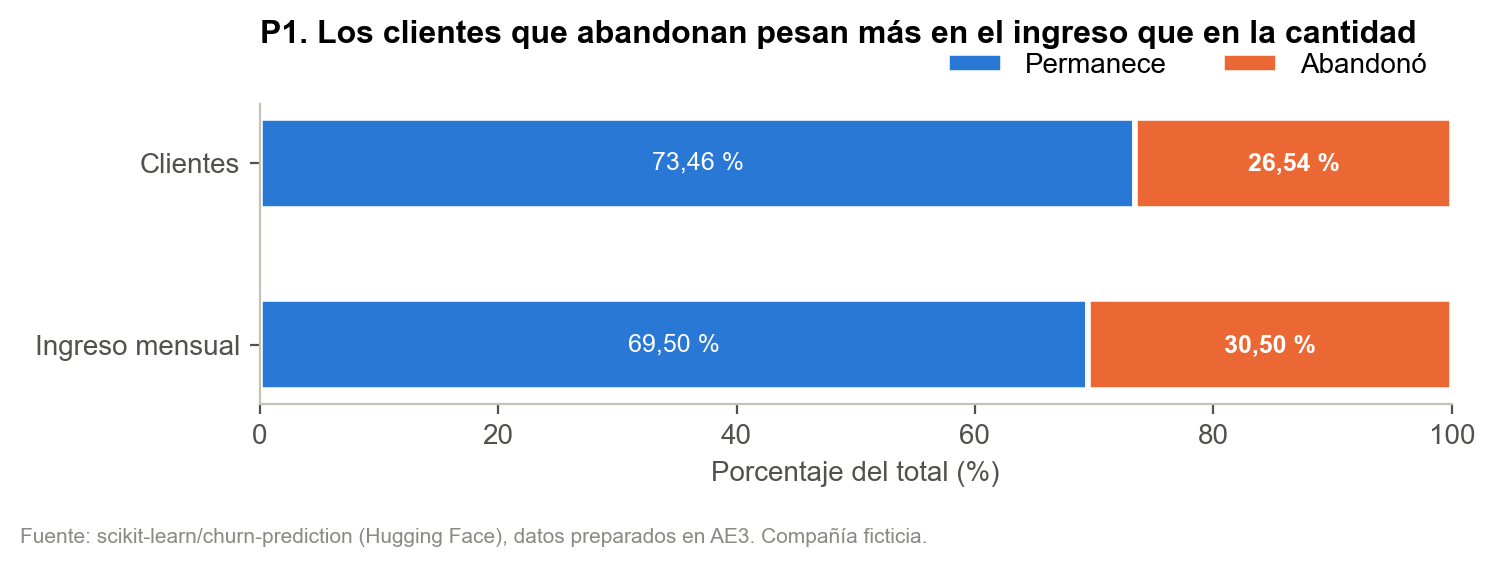

WindowsPath('C:/Users/Jose Ordoñez/OneDrive - Bodhitri/Documents/S30 - EA2 Proyecto integrador - Ideación , Diseño y Documentación Necesidad/AE4/resultados/graficos/P1_abandono_clientes_vs_ingreso.png')

In [6]:
# Barras 100 % apiladas: misma división (permanece / abandonó) medida en clientes y en ingreso mensual.
p1 = tablas["P1_resumen_general"].iloc[0]
pct_clientes = p1["tasa_abandono_pct"]
pct_ingreso = p1["ingreso_perdido_pct"]

fig, ax = plt.subplots(figsize=(7.5, 2.8))
medidas = ["Ingreso mensual", "Clientes"]
abandono = [pct_ingreso, pct_clientes]
permanece = [100 - pct_ingreso, 100 - pct_clientes]
ax.barh(medidas, permanece, color=C.AZUL, height=0.5, label="Permanece", edgecolor="white", linewidth=2)
ax.barh(medidas, abandono, left=permanece, color=C.NARANJA, height=0.5, label="Abandonó", edgecolor="white", linewidth=2)
for i in range(2):
    ax.text(permanece[i] / 2, i, f"{permanece[i]:.2f} %".replace(".", ","), ha="center", va="center", color="white", fontsize=9)
    ax.text(permanece[i] + abandono[i] / 2, i, f"{abandono[i]:.2f} %".replace(".", ","), ha="center", va="center",
            color="white", fontsize=9, fontweight="bold")
ax.set_xlim(0, 100)
ax.set_xlabel("Porcentaje del total (%)")
ax.grid(False)
ax.legend(ncol=2, loc="lower right", bbox_to_anchor=(1, 1.0), frameon=False)
ax.set_title("P1. Los clientes que abandonan pesan más en el ingreso que en la cantidad", loc="left", pad=22)
fig.tight_layout(rect=(0, 0.05, 1, 1))
guardar(fig, "P1_abandono_clientes_vs_ingreso")

### P2. ¿Cómo varía el abandono según el tipo de contrato?

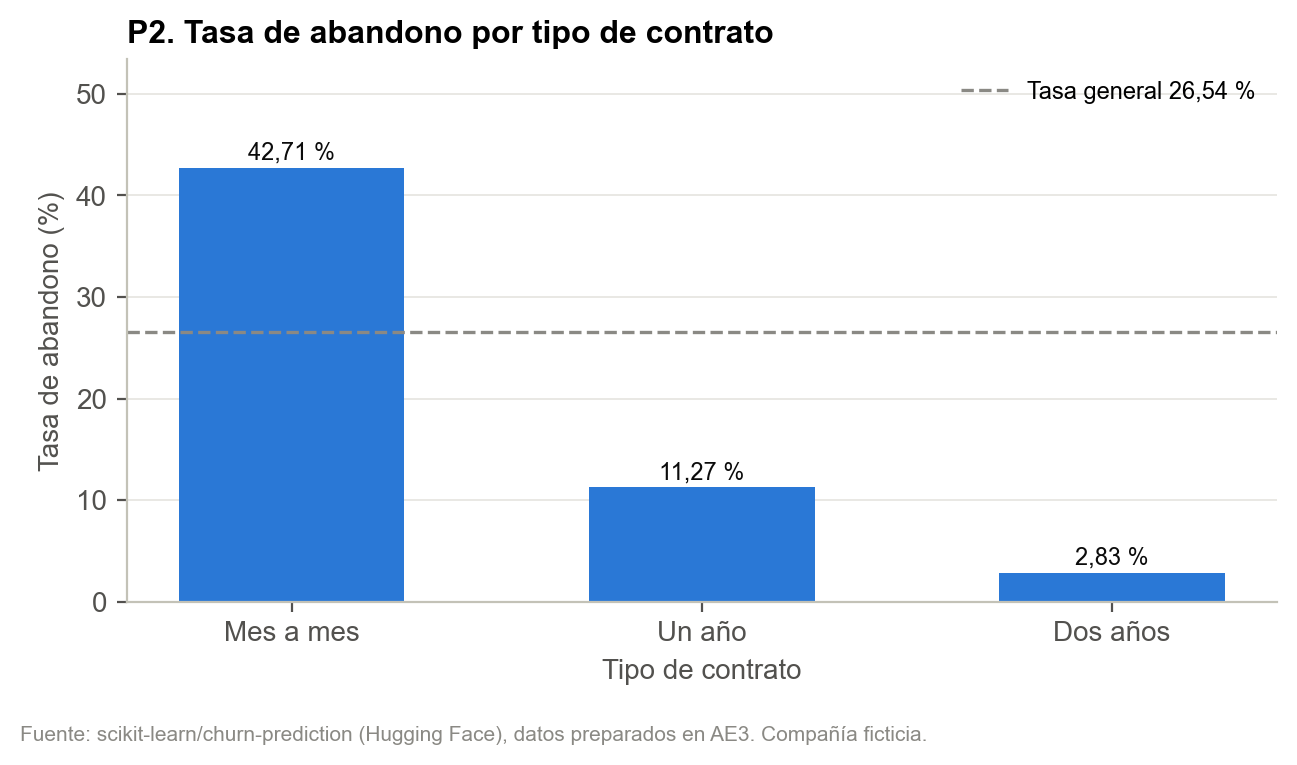

WindowsPath('C:/Users/Jose Ordoñez/OneDrive - Bodhitri/Documents/S30 - EA2 Proyecto integrador - Ideación , Diseño y Documentación Necesidad/AE4/resultados/graficos/P2_abandono_por_contrato.png')

In [7]:
fig = barras_tasa(tablas["P2_abandono_por_contrato"], "tipo_contrato",
                  "P2. Tasa de abandono por tipo de contrato", "Tipo de contrato", ancho=6.5)
guardar(fig, "P2_abandono_por_contrato")

### P3. ¿Cómo varía el abandono según la antigüedad del cliente?

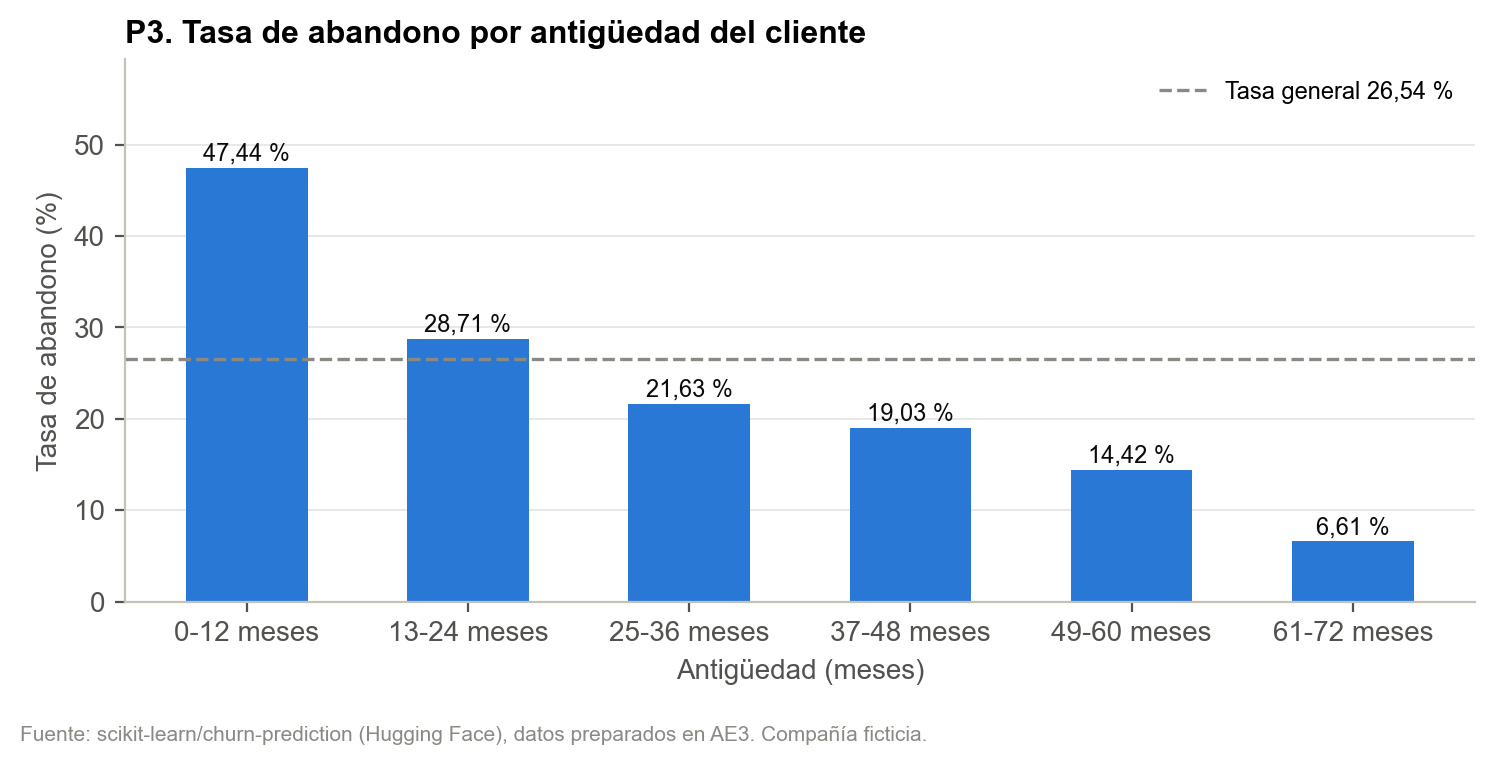

WindowsPath('C:/Users/Jose Ordoñez/OneDrive - Bodhitri/Documents/S30 - EA2 Proyecto integrador - Ideación , Diseño y Documentación Necesidad/AE4/resultados/graficos/P3_abandono_por_antiguedad.png')

In [8]:
fig = barras_tasa(tablas["P3_abandono_por_antiguedad"], "rango_antiguedad",
                  "P3. Tasa de abandono por antigüedad del cliente", "Antigüedad (meses)")
guardar(fig, "P3_abandono_por_antiguedad")

### P4. ¿Se diferencian en sus cargos los clientes que abandonan?

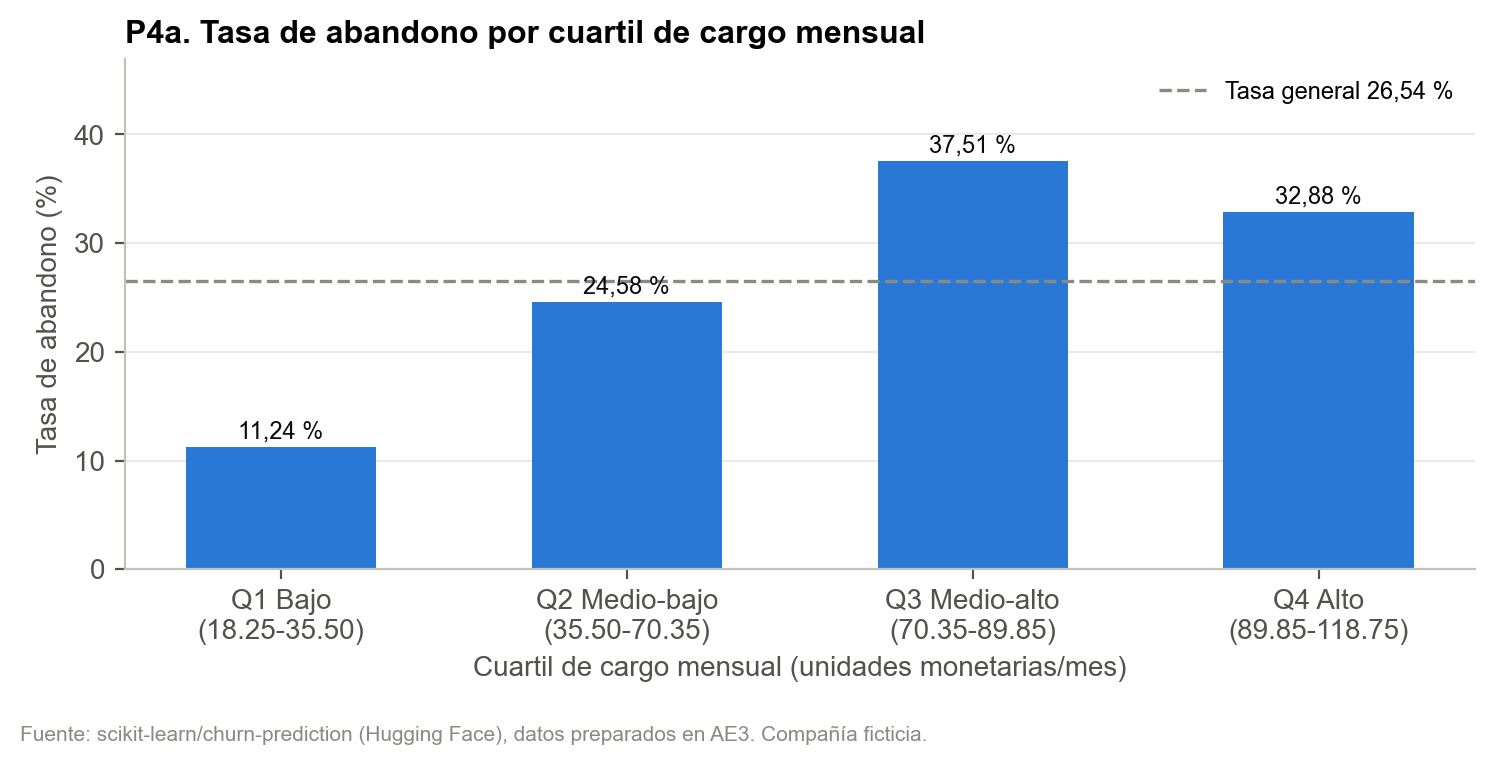

WindowsPath('C:/Users/Jose Ordoñez/OneDrive - Bodhitri/Documents/S30 - EA2 Proyecto integrador - Ideación , Diseño y Documentación Necesidad/AE4/resultados/graficos/P4a_abandono_por_cargo_mensual.png')

In [9]:
fig = barras_tasa(tablas["P4a_abandono_por_cargo_mensual"], "rango_cargo_mensual",
                  "P4a. Tasa de abandono por cuartil de cargo mensual", "Cuartil de cargo mensual (unidades monetarias/mes)")
guardar(fig, "P4a_abandono_por_cargo_mensual")

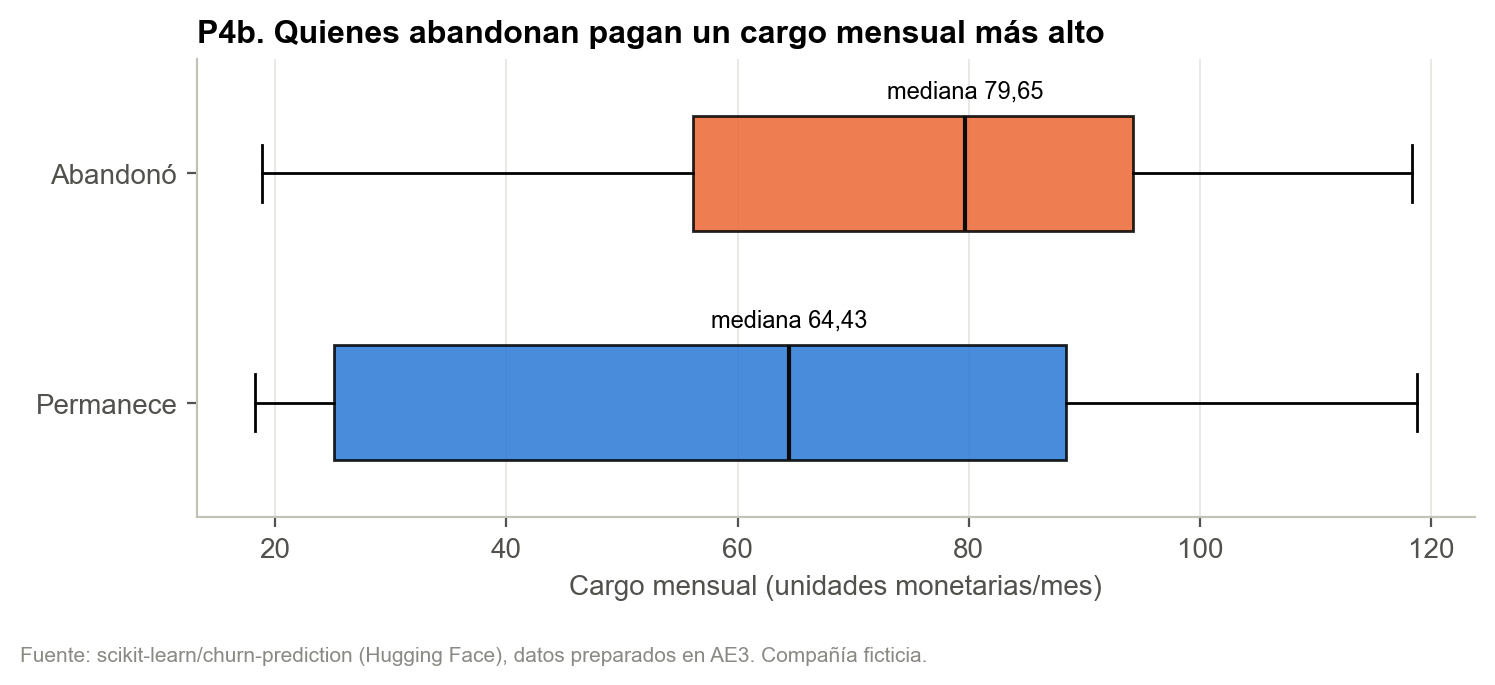

WindowsPath('C:/Users/Jose Ordoñez/OneDrive - Bodhitri/Documents/S30 - EA2 Proyecto integrador - Ideación , Diseño y Documentación Necesidad/AE4/resultados/graficos/P4b_cargo_mensual_por_abandono.png')

In [10]:
# Distribución del cargo mensual de quienes permanecen y quienes abandonan (diagrama de caja).
fig, ax = plt.subplots(figsize=(7.5, 3.4))
grupos = [df.loc[df["abandono"] == "No", "cargo_mensual"], df.loc[df["abandono"] == "Sí", "cargo_mensual"]]
caja = ax.boxplot(grupos, vert=False, labels=["Permanece", "Abandonó"], widths=0.5, patch_artist=True,
                  medianprops={"color": "#0b0b0b", "linewidth": 1.5})
for parche, color in zip(caja["boxes"], [C.AZUL, C.NARANJA]):
    parche.set_facecolor(color)
    parche.set_alpha(0.85)
for i, g in enumerate(grupos, start=1):
    ax.text(g.median(), i + 0.33, f"mediana {g.median():.2f}".replace(".", ","), ha="center", fontsize=8.5)
ax.set_xlabel("Cargo mensual (unidades monetarias/mes)")
ax.grid(axis="y", visible=False)
ax.set_title("P4b. Quienes abandonan pagan un cargo mensual más alto", loc="left")
fig.tight_layout(rect=(0, 0.05, 1, 1))
guardar(fig, "P4b_cargo_mensual_por_abandono")

### P5. ¿Hay diferencias según el método de pago y el servicio de internet?

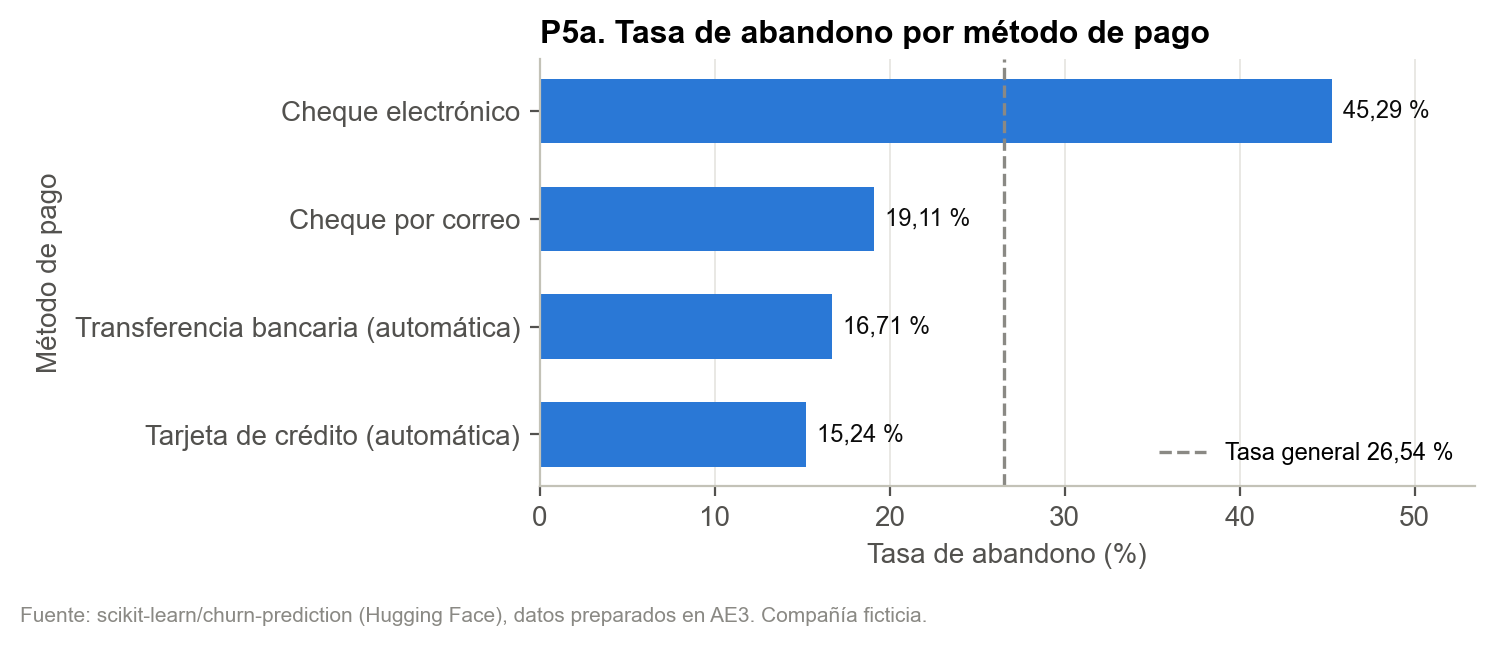

WindowsPath('C:/Users/Jose Ordoñez/OneDrive - Bodhitri/Documents/S30 - EA2 Proyecto integrador - Ideación , Diseño y Documentación Necesidad/AE4/resultados/graficos/P5a_abandono_por_metodo_pago.png')

In [11]:
fig = barras_tasa(tablas["P5a_abandono_por_metodo_pago"], "metodo_pago",
                  "P5a. Tasa de abandono por método de pago", "Método de pago", horizontal=True, alto=3.2)
guardar(fig, "P5a_abandono_por_metodo_pago")

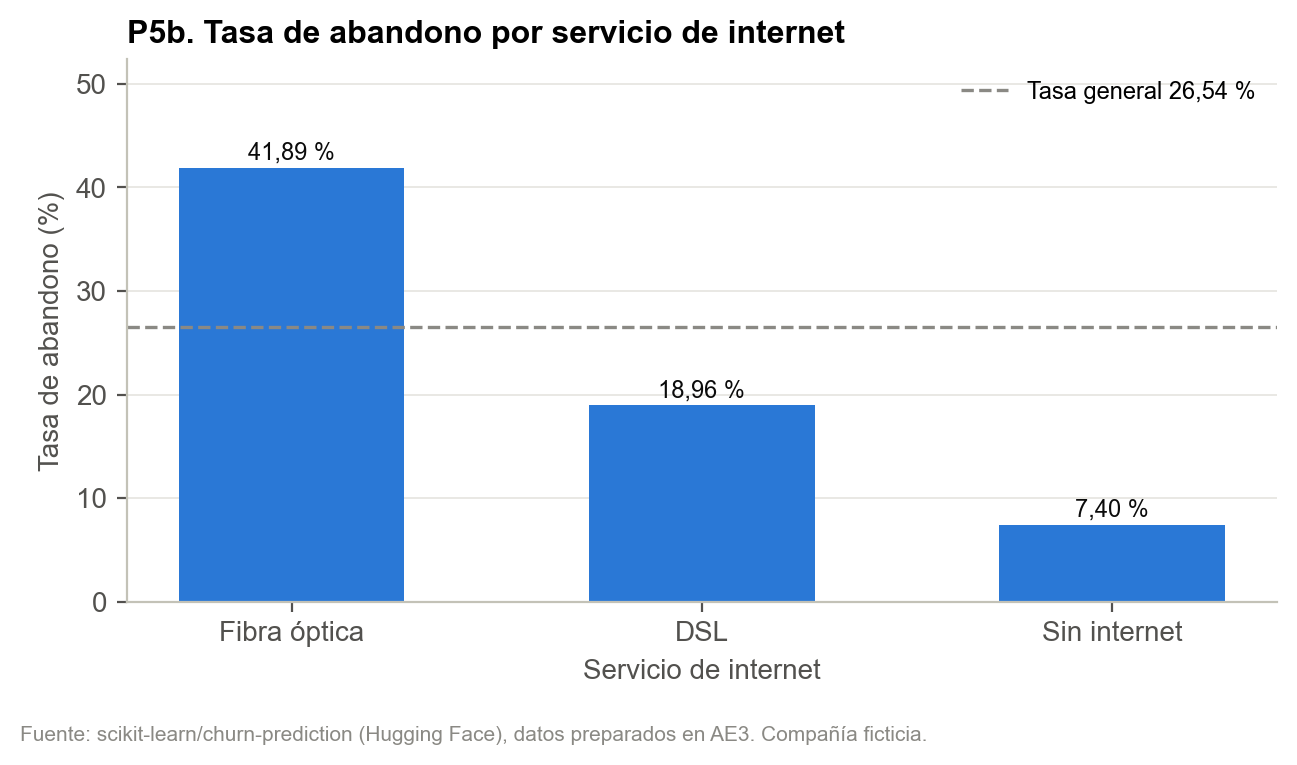

WindowsPath('C:/Users/Jose Ordoñez/OneDrive - Bodhitri/Documents/S30 - EA2 Proyecto integrador - Ideación , Diseño y Documentación Necesidad/AE4/resultados/graficos/P5b_abandono_por_internet.png')

In [12]:
fig = barras_tasa(tablas["P5b_abandono_por_internet"], "servicio_internet",
                  "P5b. Tasa de abandono por servicio de internet", "Servicio de internet", ancho=6.5)
guardar(fig, "P5b_abandono_por_internet")

### P6. ¿Qué segmentos (contrato × internet) concentran el abandono?

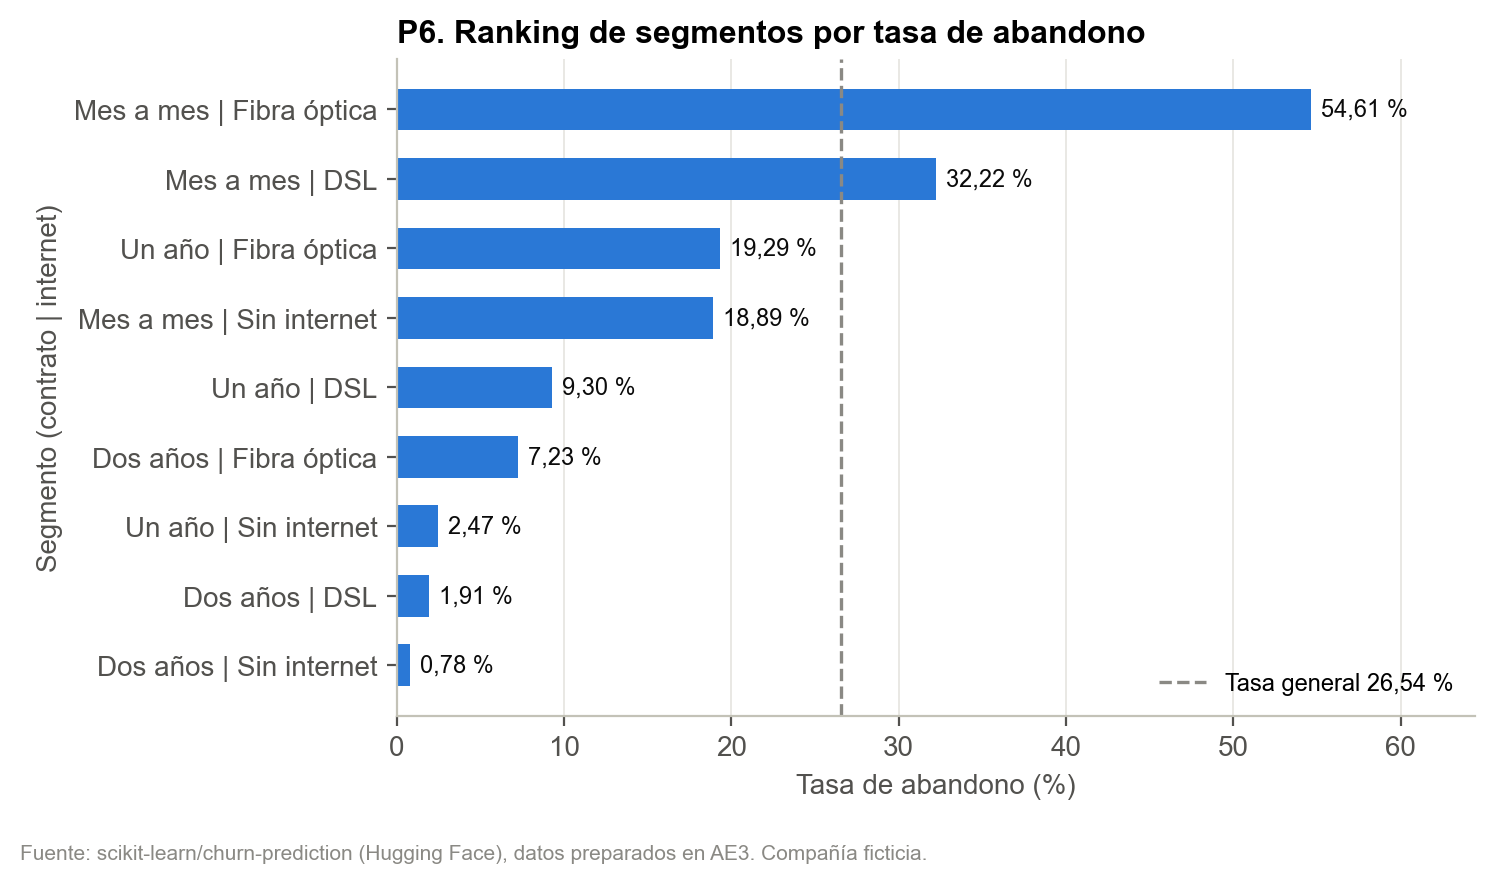

WindowsPath('C:/Users/Jose Ordoñez/OneDrive - Bodhitri/Documents/S30 - EA2 Proyecto integrador - Ideación , Diseño y Documentación Necesidad/AE4/resultados/graficos/P6_ranking_segmentos.png')

In [13]:
t6 = tablas["P6_ranking_segmentos"].copy()
t6["segmento"] = t6["tipo_contrato"] + " | " + t6["servicio_internet"]
fig = barras_tasa(t6, "segmento", "P6. Ranking de segmentos por tasa de abandono",
                  "Segmento (contrato | internet)", horizontal=True, alto=4.4)
guardar(fig, "P6_ranking_segmentos")

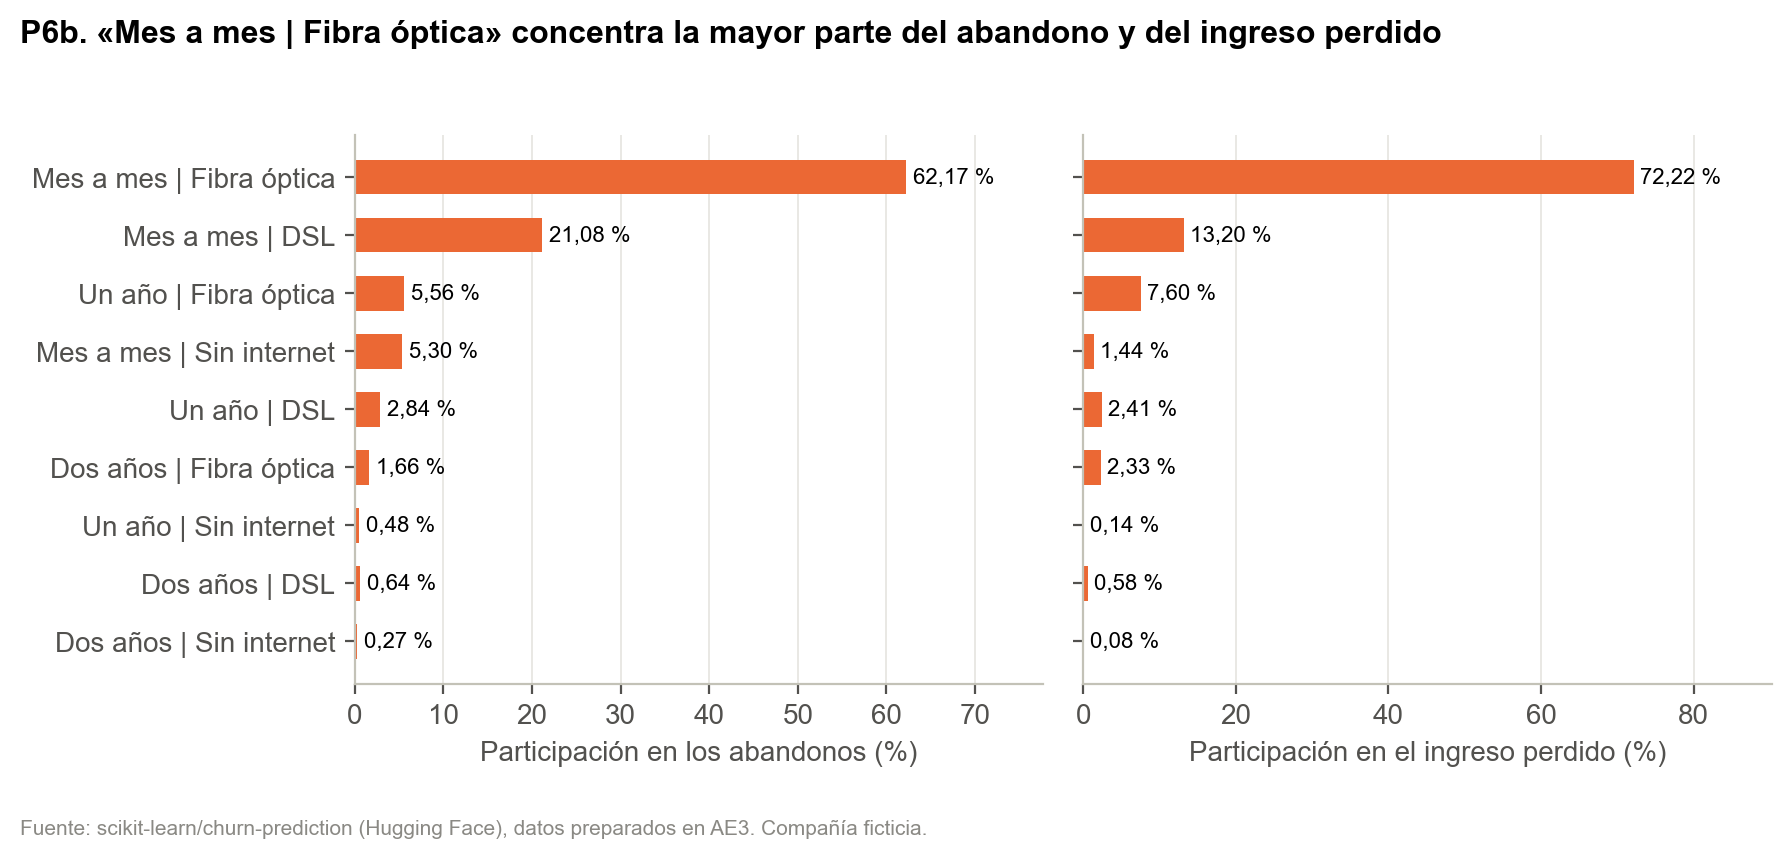

WindowsPath('C:/Users/Jose Ordoñez/OneDrive - Bodhitri/Documents/S30 - EA2 Proyecto integrador - Ideación , Diseño y Documentación Necesidad/AE4/resultados/graficos/P6b_participacion_segmentos.png')

In [14]:
# Participación de cada segmento en los abandonos y en el ingreso perdido (dos gráficos, un eje cada uno).
fig, ejes = plt.subplots(1, 2, figsize=(9, 4.2), sharey=True)
for ax, col, titulo, color in [
    (ejes[0], "participacion_abandonos_pct", "Participación en los abandonos (%)", C.NARANJA),
    (ejes[1], "participacion_ingreso_perdido_pct", "Participación en el ingreso perdido (%)", C.NARANJA),
]:
    barras = ax.barh(t6["segmento"], t6[col], color=color, height=0.6)
    for b, v in zip(barras, t6[col]):
        ax.text(b.get_width() + 0.8, b.get_y() + b.get_height() / 2, f"{v:.2f} %".replace(".", ","), va="center", fontsize=8)
    ax.set_xlim(0, t6[col].max() * 1.25)
    ax.set_xlabel(titulo)
    ax.grid(axis="y", visible=False)
ejes[0].invert_yaxis()
fig.suptitle("P6b. «Mes a mes | Fibra óptica» concentra la mayor parte del abandono y del ingreso perdido",
             x=0.01, ha="left", fontweight="bold", fontsize=11.5)
fig.tight_layout(rect=(0, 0.05, 1, 0.95))
guardar(fig, "P6b_participacion_segmentos")

## 6. Respuestas, decisiones y limitaciones

In [15]:
# Los mismos textos que muestra la aplicación de Streamlit.
for clave, p in C.PREGUNTAS.items():
    print(f"{clave}. {p['pregunta']}")
    print("  Respuesta:", p["respuesta"])
    print("  Decisión que apoya:", p["decision"])
    print("  Limitación:", p["limitacion"])
    print()

P1. ¿Qué proporción de clientes abandonó y cuánto ingreso mensual representa?
  Respuesta: 1869 de 7043 clientes abandonaron el servicio en el último mes: una tasa del 26,54 %, cerca de uno de cada cuatro clientes. Esos clientes pagaban 139130,85 al mes, el 30,50 % del ingreso mensual. El ingreso perdido pesa más que la proporción de clientes, porque se van, en promedio, clientes con cargos más altos.
  Decisión que apoya: Dimensionar el problema y fijar una línea base para medir el efecto de las campañas de retención.
  Limitación: Es una foto de un solo mes: sin fechas no se sabe si la tasa sube o baja con el tiempo.

P2. ¿Cómo varía el abandono según el tipo de contrato?
  Respuesta: El contrato mes a mes concentra el abandono: su tasa es del 42,71 %, frente al 11,27 % del contrato a un año y el 2,83 % del de dos años. Son el 55,02 % de los clientes, pero aportan el 88,55 % de los abandonos y el 86,86 % del ingreso perdido.
  Decisión que apoya: Priorizar ofertas para migrar a los c

In [16]:
print("Archivos generados:")
for ruta in sorted(CARPETA_GRAFICOS.glob("*.png")):
    print(" -", ruta.relative_to(ROOT).as_posix())
print(" -", "AE4/resultados/metricas_por_pregunta.csv")

Archivos generados:
 - AE4/resultados/graficos/P1_abandono_clientes_vs_ingreso.png
 - AE4/resultados/graficos/P2_abandono_por_contrato.png
 - AE4/resultados/graficos/P3_abandono_por_antiguedad.png
 - AE4/resultados/graficos/P4a_abandono_por_cargo_mensual.png
 - AE4/resultados/graficos/P4b_cargo_mensual_por_abandono.png
 - AE4/resultados/graficos/P5a_abandono_por_metodo_pago.png
 - AE4/resultados/graficos/P5b_abandono_por_internet.png
 - AE4/resultados/graficos/P6_ranking_segmentos.png
 - AE4/resultados/graficos/P6b_participacion_segmentos.png
 - AE4/resultados/metricas_por_pregunta.csv
